# RSICD Patch-Labeling Dataset Prep (Part A)
### Preparing everything GeoChat needs to relabel low-confidence patches

This notebook builds the **structured dataset** that Part B (GeoChat inference) will consume.
For every RSICD image, we assemble: its scene class, its 5 captions, its scene-specific candidate
vocabulary (indexed into the global vocabulary), and the fixed 7×7 grid of patch bounding boxes.

**Pipeline:**
1. Setup — imports, paths
2. Load global vocabulary + per-scene vocabulary subsets
3. Load RSICD captions JSON
4. Build per-image caption metadata
5. Build image → scene-class mapping
6. Cross-check JSON images vs. scene-labeled images
7. Build unified per-image records (scene + captions + candidate vocab)
8. Define the fixed 7×7 grid of patch bounding boxes
9. Visual sanity check of one patch
10. Verify record integrity
11. Scene-class distribution check
12. Save output files (metadata, vocab mapping, full patch-labeling dataset)
13. Final validation + zip for download


## 1. Setup

In [1]:
import os
import json
import shutil
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image

In [2]:
BASE_DIR = "/kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master"

IMG_DIR = os.path.join(BASE_DIR, "RSICD_images")
CLASSES_DIR = os.path.join(BASE_DIR, "txtclasses_rsicd")

VOCAB_DIR = "/kaggle/input/datasets/vedantbarhate007/rsicd-raster-classes/raster_classes_dataset"
GLOBAL_VOCAB_FILE = os.path.join(VOCAB_DIR, "global_vocab.json")
CLASS_TO_VOCAB_FILE = os.path.join(VOCAB_DIR, "class_to_vocab_with_indices.json")

DATASET_JSON = os.path.join(BASE_DIR, "dataset_rsicd.json")

paths = {
    "IMG_DIR": IMG_DIR,
    "CLASSES_DIR": CLASSES_DIR,
    "GLOBAL_VOCAB_FILE": GLOBAL_VOCAB_FILE,
    "CLASS_TO_VOCAB_FILE": CLASS_TO_VOCAB_FILE,
    "DATASET_JSON": DATASET_JSON,
}

for name, path in paths.items():
    print(f"{name}:")
    print(f"  {path}")
    print(f"  {'OK' if os.path.exists(path) else 'MISSING'}")
    print()

IMG_DIR:
  /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/RSICD_images
  OK

CLASSES_DIR:
  /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/txtclasses_rsicd
  OK

GLOBAL_VOCAB_FILE:
  /kaggle/input/datasets/vedantbarhate007/rsicd-raster-classes/raster_classes_dataset/global_vocab.json
  OK

CLASS_TO_VOCAB_FILE:
  /kaggle/input/datasets/vedantbarhate007/rsicd-raster-classes/raster_classes_dataset/class_to_vocab_with_indices.json
  OK

DATASET_JSON:
  /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/dataset_rsicd.json
  OK



In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


## 2. Load Global Vocabulary + Per-Scene Vocabulary Subsets

`global_vocab.json` is the deduplicated, indexed master vocabulary. `class_to_vocab_with_indices.json`
maps each RSICD scene class to its relevant subset of that vocabulary (by index).

In [4]:
with open(GLOBAL_VOCAB_FILE, "r") as f:
    global_vocab = json.load(f)

with open(CLASS_TO_VOCAB_FILE, "r") as f:
    class_to_vocab = json.load(f)

print("Global vocabulary type:", type(global_vocab))
print("Number of global terms:", len(global_vocab))

print("\nNumber of scene classes:", len(class_to_vocab))
print("\nScene classes:")
print(list(class_to_vocab.keys()))

Global vocabulary type: <class 'list'>
Number of global terms: 210

Number of scene classes: 31

Scene classes:
['airport', 'bareland', 'baseballfield', 'beach', 'bridge', 'center', 'church', 'commercial', 'denseresidential', 'desert', 'farmland', 'forest', 'industrial', 'meadow', 'mediumresidential', 'mountain', 'park', 'parking', 'playfields', 'playground', 'pond', 'port', 'railwaystation', 'resort', 'river', 'school', 'sparseresidential', 'square', 'stadium', 'storagetanks', 'viaduct']


In [5]:
first_scene = list(class_to_vocab.keys())[0]

print("Example scene:", first_scene)
print()
print(json.dumps(class_to_vocab[first_scene], indent=2)[:3000])

Example scene: airport

[
  {
    "index": 0,
    "term": "aeroplane"
  },
  {
    "index": 1,
    "term": "airport"
  },
  {
    "index": 3,
    "term": "apron"
  },
  {
    "index": 23,
    "term": "building"
  },
  {
    "index": 29,
    "term": "cargo"
  },
  {
    "index": 37,
    "term": "container"
  },
  {
    "index": 70,
    "term": "grass"
  },
  {
    "index": 86,
    "term": "land"
  },
  {
    "index": 103,
    "term": "parking lot"
  },
  {
    "index": 137,
    "term": "road"
  },
  {
    "index": 144,
    "term": "runway"
  },
  {
    "index": 174,
    "term": "storage tank"
  },
  {
    "index": 182,
    "term": "tarmac"
  },
  {
    "index": 184,
    "term": "terminal"
  },
  {
    "index": 189,
    "term": "tree"
  },
  {
    "index": 196,
    "term": "vehicle"
  },
  {
    "index": 203,
    "term": "water"
  }
]


In [6]:
print("First 10 global vocabulary entries:")

if isinstance(global_vocab, dict):
    for i, (k, v) in enumerate(global_vocab.items()):
        print(repr(k), ":", repr(v))
        if i >= 9:
            break
elif isinstance(global_vocab, list):
    for i, v in enumerate(global_vocab[:10]):
        print(i, ":", repr(v))

First 10 global vocabulary entries:
0 : {'index': 0, 'term': 'aeroplane'}
1 : {'index': 1, 'term': 'airport'}
2 : {'index': 2, 'term': 'apartment'}
3 : {'index': 3, 'term': 'apron'}
4 : {'index': 4, 'term': 'asphalt'}
5 : {'index': 5, 'term': 'awning'}
6 : {'index': 6, 'term': 'badminton court'}
7 : {'index': 7, 'term': 'ball'}
8 : {'index': 8, 'term': 'bank'}
9 : {'index': 9, 'term': 'bare ground'}


In [7]:
# Global index <-> term lookups
idx_to_term = {item["index"]: item["term"] for item in global_vocab}
term_to_idx = {item["term"]: item["index"] for item in global_vocab}

# Scene -> list of allowed terms / indices
scene_to_terms = {
    scene: [item["term"] for item in terms]
    for scene, terms in class_to_vocab.items()
}
scene_to_indices = {
    scene: [item["index"] for item in terms]
    for scene, terms in class_to_vocab.items()
}

print("Global vocabulary:", len(idx_to_term))
print("Scenes:", len(scene_to_terms))

print("\nAirport:")
for idx in scene_to_indices["airport"]:
    print(idx, "->", idx_to_term[idx])

Global vocabulary: 210
Scenes: 31

Airport:
0 -> aeroplane
1 -> airport
3 -> apron
23 -> building
29 -> cargo
37 -> container
70 -> grass
86 -> land
103 -> parking lot
137 -> road
144 -> runway
174 -> storage tank
182 -> tarmac
184 -> terminal
189 -> tree
196 -> vehicle
203 -> water


## 3. Load RSICD Captions JSON

In [8]:
print("Dataset JSON:")
print(DATASET_JSON)
print("Exists:", os.path.exists(DATASET_JSON))

with open(DATASET_JSON, "r") as f:
    rsicd_data = json.load(f)

print("\nTop-level keys:")
print(rsicd_data.keys())

print("\nNumber of images in JSON:")
print(len(rsicd_data["images"]))

Dataset JSON:
/kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/dataset_rsicd.json
Exists: True

Top-level keys:
dict_keys(['images', 'dataset'])

Number of images in JSON:
10921


In [9]:
sample = rsicd_data["images"][0]
print(json.dumps(sample, indent=2)[:5000])

{
  "filename": "airport_1.jpg",
  "imgid": 0,
  "sentences": [
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "in",
        "an",
        "airport"
      ],
      "raw": "many planes are parked next to a long building in an airport .",
      "imgid": 0,
      "sentid": 0
    },
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "in",
        "an",
        "airport"
      ],
      "raw": "many planes are parked next to a long building in an airport .",
      "imgid": 0,
      "sentid": 1
    },
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "in",
        "an",
        "airport"
      ],
      "raw": "man

## 4. Build Per-Image Caption Metadata

In [10]:
image_metadata = {}

for item in rsicd_data["images"]:
    filename = item["filename"]
    captions = [sentence["raw"] for sentence in item["sentences"]]

    image_metadata[filename] = {
        "imgid": item["imgid"],
        "captions": captions,
        "split": item["split"]
    }

print("Images indexed:", len(image_metadata))

example_filename = list(image_metadata.keys())[0]
print("\nFilename:", example_filename)
print("Split:", image_metadata[example_filename]["split"])
print("\nCaptions:")
for i, caption in enumerate(image_metadata[example_filename]["captions"], 1):
    print(f"{i}. {caption}")

Images indexed: 10921

Filename: airport_1.jpg
Split: train

Captions:
1. many planes are parked next to a long building in an airport .
2. many planes are parked next to a long building in an airport .
3. many planes are parked next to a long building in an airport .
4. many planes are parked next to a long building in an airport .
5. many planes are parked next to a long building in an airport .


## 5. Build Image → Scene-Class Mapping

Reusing the `txtclasses_rsicd` per-class label files (same approach as the earlier vocabulary
generation and whole-image classification notebooks).

In [11]:
image_to_scene = {}

for filename in os.listdir(CLASSES_DIR):
    if not filename.lower().endswith(".txt"):
        continue

    # e.g. "DenseResidential.txt" -> "denseresidential"
    scene_name = os.path.splitext(filename)[0].lower()
    txt_path = os.path.join(CLASSES_DIR, filename)

    with open(txt_path, "r") as f:
        for line in f:
            image_name = line.strip()
            if not image_name:
                continue
            image_to_scene[image_name] = scene_name

print("Images mapped to scene classes:", len(image_to_scene))
print("\nExample mappings:")
for image_name, scene in list(image_to_scene.items())[:20]:
    print(f"{image_name} -> {scene}")

Images mapped to scene classes: 10921

Example mappings:
bareland_1.jpg -> bareland
bareland_10.jpg -> bareland
bareland_100.jpg -> bareland
bareland_101.jpg -> bareland
bareland_102.jpg -> bareland
bareland_103.jpg -> bareland
bareland_104.jpg -> bareland
bareland_105.jpg -> bareland
bareland_106.jpg -> bareland
bareland_107.jpg -> bareland
bareland_108.jpg -> bareland
bareland_109.jpg -> bareland
bareland_11.jpg -> bareland
bareland_110.jpg -> bareland
bareland_111.jpg -> bareland
bareland_112.jpg -> bareland
bareland_113.jpg -> bareland
bareland_114.jpg -> bareland
bareland_115.jpg -> bareland
bareland_116.jpg -> bareland


## 6. Cross-Check: JSON Images vs. Scene-Labeled Images

In [12]:
json_images = set(image_metadata.keys())
scene_images = set(image_to_scene.keys())

missing_scene = json_images - scene_images
extra_scene = scene_images - json_images

print("Images in JSON:", len(json_images))
print("Images in scene files:", len(scene_images))

print("\nMissing scene labels:", len(missing_scene))
print("Extra scene entries:", len(extra_scene))

if missing_scene:
    print("\nFirst missing examples:")
    print(list(missing_scene)[:20])

if extra_scene:
    print("\nFirst extra examples:")
    print(list(extra_scene)[:20])

Images in JSON: 10921
Images in scene files: 10921

Missing scene labels: 0
Extra scene entries: 0


## 7. Build Unified Per-Image Records

Combine scene class, captions, and the scene's candidate vocabulary (terms + global indices)
into a single record per image.

In [13]:
records = {}

for filename, metadata in image_metadata.items():
    scene = image_to_scene.get(filename)
    if scene is None:
        continue

    records[filename] = {
        "filename": filename,
        "imgid": metadata["imgid"],
        "scene": scene,
        "captions": metadata["captions"],
        "split": metadata["split"],
        "candidate_terms": scene_to_terms[scene],
        "candidate_indices": scene_to_indices[scene]
    }

print("Unified records:", len(records))

example = records["airport_1.jpg"]
print(json.dumps(example, indent=2))

Unified records: 10921
{
  "filename": "airport_1.jpg",
  "imgid": 0,
  "scene": "airport",
  "captions": [
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport ."
  ],
  "split": "train",
  "candidate_terms": [
    "aeroplane",
    "airport",
    "apron",
    "building",
    "cargo",
    "container",
    "grass",
    "land",
    "parking lot",
    "road",
    "runway",
    "storage tank",
    "tarmac",
    "terminal",
    "tree",
    "vehicle",
    "water"
  ],
  "candidate_indices": [
    0,
    1,
    3,
    23,
    29,
    37,
    70,
    86,
    103,
    137,
    144,
    174,
    182,
    184,
    189,
    196,
    203
  ]
}


## 8. Define the Fixed 7×7 Grid of Patch Bounding Boxes

RSICD images are natively 224×224. A 7×7 grid gives 32×32 pixel cells -- this grid definition
(cell id, row/col, pixel bbox) is shared across all images and computed once.

In [14]:
IMAGE_SIZE = 224
GRID_SIZE = 7
CELL_SIZE = IMAGE_SIZE // GRID_SIZE

print("Image size :", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Grid size  :", GRID_SIZE, "x", GRID_SIZE)
print("Cell size  :", CELL_SIZE, "x", CELL_SIZE)

Image size : 224 x 224
Grid size  : 7 x 7
Cell size  : 32 x 32


In [15]:
def get_grid_cells(image_size=224, grid_size=7):
    cell_size = image_size // grid_size
    cells = []

    for row in range(grid_size):
        for col in range(grid_size):
            x1 = col * cell_size
            y1 = row * cell_size
            x2 = x1 + cell_size
            y2 = y1 + cell_size

            cells.append({
                "row": row,
                "col": col,
                "cell_id": row * grid_size + col,
                "bbox": [x1, y1, x2, y2]
            })

    return cells


grid_cells = get_grid_cells()

print("Total cells:", len(grid_cells))
for cell in grid_cells[:10]:
    print(cell)

Total cells: 49
{'row': 0, 'col': 0, 'cell_id': 0, 'bbox': [0, 0, 32, 32]}
{'row': 0, 'col': 1, 'cell_id': 1, 'bbox': [32, 0, 64, 32]}
{'row': 0, 'col': 2, 'cell_id': 2, 'bbox': [64, 0, 96, 32]}
{'row': 0, 'col': 3, 'cell_id': 3, 'bbox': [96, 0, 128, 32]}
{'row': 0, 'col': 4, 'cell_id': 4, 'bbox': [128, 0, 160, 32]}
{'row': 0, 'col': 5, 'cell_id': 5, 'bbox': [160, 0, 192, 32]}
{'row': 0, 'col': 6, 'cell_id': 6, 'bbox': [192, 0, 224, 32]}
{'row': 1, 'col': 0, 'cell_id': 7, 'bbox': [0, 32, 32, 64]}
{'row': 1, 'col': 1, 'cell_id': 8, 'bbox': [32, 32, 64, 64]}
{'row': 1, 'col': 2, 'cell_id': 9, 'bbox': [64, 32, 96, 64]}


## 9. Visual Sanity Check — Crop and View One Patch

Image dimensions: (224, 224)
Cell: 24
Row, Col: 3 3
BBox: [96, 96, 128, 128]
Patch size: (32, 32)


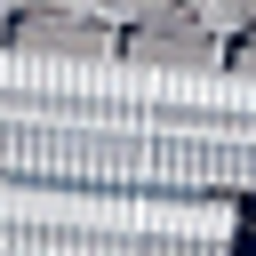

In [16]:
test_filename = "airport_1.jpg"
test_image_path = os.path.join(IMG_DIR, test_filename)

image = Image.open(test_image_path).convert("RGB")
print("Image dimensions:", image.size)

# Take center cell: row 3, col 3
test_cell = grid_cells[24]
bbox = test_cell["bbox"]
patch = image.crop(bbox)

print("Cell:", test_cell["cell_id"])
print("Row, Col:", test_cell["row"], test_cell["col"])
print("BBox:", bbox)
print("Patch size:", patch.size)

display(patch.resize((256, 256)))

## 10. Verify Record Integrity

Check every record has: a valid scene present in the vocabulary mapping, exactly 5 captions,
a non-empty candidate vocabulary, and consistent term/index pairs.

In [17]:
errors = []

for filename, record in records.items():
    if record["scene"] not in scene_to_terms:
        errors.append(f"{filename}: scene not found in vocabulary mapping")

    if len(record["captions"]) != 5:
        errors.append(f"{filename}: expected 5 captions, got {len(record['captions'])}")

    if len(record["candidate_terms"]) == 0:
        errors.append(f"{filename}: empty candidate vocabulary")

    for term, idx in zip(record["candidate_terms"], record["candidate_indices"]):
        if term_to_idx.get(term) != idx:
            errors.append(f"{filename}: mismatch between term '{term}' and index {idx}")

print("================================")
print("VERIFICATION")
print("================================")
print("Total records:", len(records))
print("Errors:", len(errors))

if errors:
    print("\nFirst errors:")
    for error in errors[:20]:
        print("-", error)
else:
    print("All records passed verification.")

VERIFICATION
Total records: 10921
Errors: 0
All records passed verification.


## 11. Scene-Class Distribution Check

In [18]:
scene_counts = Counter(record["scene"] for record in records.values())

print("Number of scene classes:", len(scene_counts))
print()
for scene, count in sorted(scene_counts.items()):
    print(f"{scene:25s} {count}")

Number of scene classes: 31

airport                   420
bareland                  310
baseballfield             276
beach                     400
bridge                    459
center                    260
church                    240
commercial                350
denseresidential          410
desert                    300
farmland                  370
forest                    250
industrial                390
meadow                    280
mediumresidential         290
mountain                  340
park                      350
parking                   390
playfields                661
playground                370
pond                      420
port                      389
railwaystation            260
resort                    290
river                     410
school                    300
sparseresidential         300
square                    330
stadium                   290
storagetanks              396
viaduct                   420


## 12. Save Output Files

Three files, ready for Part B (GeoChat inference):
- `image_scene_metadata.json` — per-image scene, split, captions
- `scene_vocab_mapping.json` — per-scene candidate terms + global indices
- `patch_labeling_dataset.json` — the full dataset: per image, its scene, captions, candidate
  vocabulary, and the 49 grid-cell bounding boxes GeoChat will be queried on

In [19]:
image_scene_metadata = {}

for filename, record in records.items():
    image_scene_metadata[filename] = {
        "filename": filename,
        "imgid": record["imgid"],
        "scene": record["scene"],
        "split": record["split"],
        "captions": record["captions"]
    }

OUTPUT_DIR = "/kaggle/working/eric_3_part_a"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_METADATA_FILE = os.path.join(OUTPUT_DIR, "image_scene_metadata.json")

with open(IMAGE_METADATA_FILE, "w") as f:
    json.dump(image_scene_metadata, f, indent=2)

print("Saved:")
print(IMAGE_METADATA_FILE)

Saved:
/kaggle/working/eric_3_part_a/image_scene_metadata.json


In [20]:
scene_vocab_mapping = {}

for scene in sorted(scene_to_terms.keys()):
    scene_vocab_mapping[scene] = {
        "terms": scene_to_terms[scene],
        "global_indices": scene_to_indices[scene]
    }

SCENE_VOCAB_FILE = os.path.join(OUTPUT_DIR, "scene_vocab_mapping.json")

with open(SCENE_VOCAB_FILE, "w") as f:
    json.dump(scene_vocab_mapping, f, indent=2)

print("Saved:")
print(SCENE_VOCAB_FILE)

Saved:
/kaggle/working/eric_3_part_a/scene_vocab_mapping.json


In [21]:
grid_definition = []

for cell in grid_cells:
    grid_definition.append({
        "cell_id": cell["cell_id"],
        "row": cell["row"],
        "col": cell["col"],
        "bbox": cell["bbox"]
    })

print("Grid cells:", len(grid_definition))

Grid cells: 49


In [22]:
patch_labeling_dataset = []

for filename, record in records.items():
    item = {
        "filename": filename,
        "imgid": record["imgid"],
        "split": record["split"],

        "scene": record["scene"],
        "captions": record["captions"],

        "candidate_terms": record["candidate_terms"],
        "candidate_indices": record["candidate_indices"],

        "grid_size": 7,
        "cell_size": 32,
        "image_size": 224,
        "cells": grid_definition
    }

    patch_labeling_dataset.append(item)

print("Images prepared:", len(patch_labeling_dataset))
print("Cells per image:", len(grid_definition))
print("Total patch regions:", len(patch_labeling_dataset) * len(grid_definition))

Images prepared: 10921
Cells per image: 49
Total patch regions: 535129


In [23]:
PATCH_DATASET_FILE = os.path.join(OUTPUT_DIR, "patch_labeling_dataset.json")

with open(PATCH_DATASET_FILE, "w") as f:
    json.dump(patch_labeling_dataset, f, indent=2)

print("Saved:")
print(PATCH_DATASET_FILE)

Saved:
/kaggle/working/eric_3_part_a/patch_labeling_dataset.json


In [24]:
sample = patch_labeling_dataset[0]
print(json.dumps(sample, indent=2))

{
  "filename": "airport_1.jpg",
  "imgid": 0,
  "split": "train",
  "scene": "airport",
  "captions": [
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport ."
  ],
  "candidate_terms": [
    "aeroplane",
    "airport",
    "apron",
    "building",
    "cargo",
    "container",
    "grass",
    "land",
    "parking lot",
    "road",
    "runway",
    "storage tank",
    "tarmac",
    "terminal",
    "tree",
    "vehicle",
    "water"
  ],
  "candidate_indices": [
    0,
    1,
    3,
    23,
    29,
    37,
    70,
    86,
    103,
    137,
    144,
    174,
    182,
    184,
    189,
    196,
    203
  ],
  "grid_size": 7,
  "cell_size": 32,
  "image_size": 224,
  "cells": [
    {
      "cell_id"

## 13. Final Validation + Zip for Download

In [25]:
with open(PATCH_DATASET_FILE, "r") as f:
    test_data = json.load(f)

assert len(test_data) == 10921

for item in test_data:
    assert os.path.basename(item["filename"]) == item["filename"]
    assert item["scene"] in scene_vocab_mapping
    assert len(item["captions"]) == 5
    assert len(item["candidate_terms"]) == len(item["candidate_indices"])
    assert len(item["cells"]) == 49

    for cell in item["cells"]:
        assert len(cell["bbox"]) == 4

print("================================")
print("FINAL VALIDATION PASSED")
print("================================")
print("Images :", len(test_data))
print("Scenes :", len(scene_vocab_mapping))
print("Global vocabulary :", len(global_vocab))
print("Cells/image :", len(test_data[0]["cells"]))
print("Total patches :", len(test_data) * 49)

print("\nOutput files:")
print("1.", IMAGE_METADATA_FILE)
print("2.", SCENE_VOCAB_FILE)
print("3.", PATCH_DATASET_FILE)

FINAL VALIDATION PASSED
Images : 10921
Scenes : 31
Global vocabulary : 210
Cells/image : 49
Total patches : 535129

Output files:
1. /kaggle/working/eric_3_part_a/image_scene_metadata.json
2. /kaggle/working/eric_3_part_a/scene_vocab_mapping.json
3. /kaggle/working/eric_3_part_a/patch_labeling_dataset.json


In [26]:
ZIP_PATH = "/kaggle/working/ERIC3_Part_A_Raster_Labeling_Dataset.zip"

shutil.make_archive(
    "/kaggle/working/ERIC3_Part_A_Raster_Labeling_Dataset",
    "zip",
    OUTPUT_DIR
)

print("Created:")
print(ZIP_PATH)

Created:
/kaggle/working/ERIC3_Part_A_Raster_Labeling_Dataset.zip


### Output Summary

| File | Contents |
|---|---|
| `image_scene_metadata.json` | Per-image scene class, split, and 5 captions |
| `scene_vocab_mapping.json` | Per-scene candidate terms + global vocabulary indices |
| `patch_labeling_dataset.json` | **Full dataset for Part B** — per image: scene, captions, candidate vocab, and 49 grid-cell bounding boxes |

**Next (Notebook 2 — Part B):** set up GeoChat, load one RSICD image, verify normal inference,
implement region/bounding-box queries using this dataset's grid cells, and generate patch labels
for low-confidence patches identified from the RemoteCLIP baseline.
